	检查数据质量、组分数量和产率分布

In [1]:
import sys
from pathlib import Path
import pandas as pd

print(sys.executable)
print("找到 Excel 文件", Path("data/raw/Dreher_and_Doyle_input_data.xlsx").is_file())

c:\Users\eric_lu\Documents\ChatGPT\ML\.venv\Scripts\python.exe
找到 Excel 文件 True


In [2]:
from pathlib import Path
import pandas as pd

path = Path("data/raw/Dreher_and_Doyle_input_data.xlsx")

with pd.ExcelFile(path, engine="openpyxl") as workbook:
    print("工作表", workbook.sheet_names)

    if "FullCV_01" in workbook.sheet_names:
        df = workbook.parse("FullCV_01")
        print("行数和列数", df.shape)
        print("列名", df.columns.tolist())
        display(df.head(3))

工作表 ['FullCV_01', 'FullCV_02', 'FullCV_03', 'FullCV_04', 'FullCV_05', 'FullCV_06', 'FullCV_07', 'FullCV_08', 'FullCV_09', 'FullCV_10', 'Test1', 'Test2', 'Test3', 'Test4', 'Plates1-3', 'Plate2_new']
行数和列数 (3955, 5)
列名 ['Ligand', 'Additive', 'Base', 'Aryl halide', 'Output']


C:\Users\eric_lu\AppData\Local\Temp\ipykernel_16936\302302655.py:10: Pandas4Warning: ExcelFile.parse is deprecated. Use pd.read_excel instead.
  df = workbook.parse("FullCV_01")


,Ligand,Additive,Base,Aryl halide,Output
0,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P([C@@]3(C[...,CC1=CC(C)=NO1,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,ClC1=NC=CC=C1,70.410458
1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P([C@@]3(C[...,O=C(OC)C1=CC=NO1,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,BrC1=NC=CC=C1,11.064457
2,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C3CCCCC3)...,O=C(OC)C1=CC=NO1,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,IC1=CC=C(CC)C=C1,10.223550


In [3]:
print("Missing values by column:")
print(df.isna().sum())

yield_values = df["Output"]

print("\nYield data type:", yield_values.dtype)
print("Zero-yield records:", yield_values.eq(0).sum())
print("Yield summary:")
print(yield_values.describe())

component_columns = ["Aryl halide", "Ligand", "Base", "Additive"]

print("\nUnique components by role (excluding missing values):")
print(df[component_columns].nunique())

Missing values by column:
Ligand         0
Additive       0
Base           0
Aryl halide    0
Output         0
dtype: int64

Yield data type: float64
Zero-yield records: 236
Yield summary:
count    3955.000000
mean       33.085259
std        27.291205
min         0.000000
25%         7.877560
50%        28.761729
75%        53.278687
max        99.999990
Name: Output, dtype: float64

Unique components by role (excluding missing values):
Aryl halide    15
Ligand          4
Base            3
Additive       22
dtype: int64


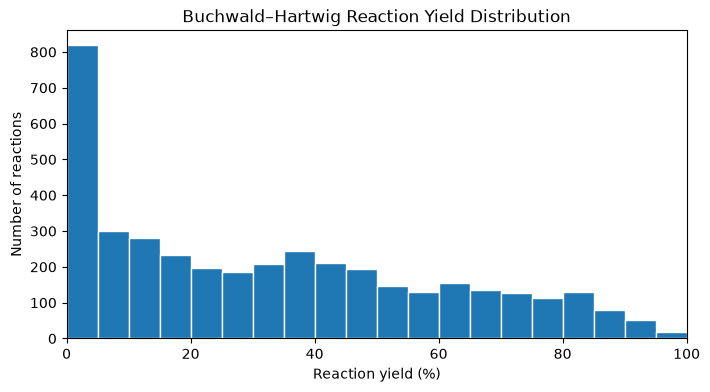

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["Output"], bins=range(0, 101, 5), edgecolor="white")

ax.set(
    title="Buchwald–Hartwig Reaction Yield Distribution",
    xlabel="Reaction yield (%)",
    ylabel="Number of reactions",
    xlim=(0, 100),
)

plt.show()

In [5]:
yields = df["Output"]

below_5 = yields.lt(5).sum()
at_least_80 = yields.ge(80).sum()

print(f"Yield below 5%: {below_5} reactions ({below_5 / len(yields):.1%})")
print(f"Yield at least 80%: {at_least_80} reactions ({at_least_80 / len(yields):.1%})")

Yield below 5%: 819 reactions (20.7%)
Yield at least 80%: 280 reactions (7.1%)


In [6]:
component_columns = ["Aryl halide", "Ligand", "Base", "Additive"]

combination_counts = df.groupby(component_columns).size()
all_combinations = pd.MultiIndex.from_product(
    [df[column].unique() for column in component_columns],
    names=component_columns,
)
missing_combinations = all_combinations.difference(combination_counts.index)

print("Exact duplicate rows:", df.duplicated().sum())
print("Combinations with multiple rows:", combination_counts.gt(1).sum())
print("Observed combinations:", len(combination_counts))
print("Possible combinations:", len(all_combinations))
print("Missing combinations:", len(missing_combinations))

display(missing_combinations.to_frame(index=False).head())

Exact duplicate rows: 0
Combinations with multiple rows: 0
Observed combinations: 3955
Possible combinations: 3960
Missing combinations: 5


,Aryl halide,Ligand,Base,Additive
0,BrC1=CC=C(C(F)(F)F)C=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C(C)(C)C)...,CN1CCCN2C1=NCCC2,CC1=NOC=C1
1,ClC1=CC=C(CC)C=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C(C)(C)C)...,CC(C)(C)/N=C(N(C)C)/N(C)C,C1(C2=CC=CC=C2)=CON=C1
2,ClC1=CC=C(CC)C=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C(C)(C)C)...,CC(C)(C)/N=C(N(C)C)/N(C)C,C1(C2=CC=CC=C2)=NOC=C1
3,IC1=CC=C(C(F)(F)F)C=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C(C)(C)C)...,CN1CCCN2C1=NCCC2,CC1=NOC=C1
4,IC1=CN=CC=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C(C)(C)C)...,CC(C)(C)/N=C(N(C)C)/N(C)C,C1(C2=CC=CC=C2)=NOC=C1


In [7]:
from pathlib import Path

report_dir = Path("reports")
report_dir.mkdir(exist_ok=True)

fig.savefig(report_dir / "yield_distribution.png", dpi=200, bbox_inches="tight")

missing_combinations.to_frame(index=False).to_csv(
    report_dir / "missing_combinations.csv", index=False
)

print("Saved the yield histogram and missing combinations to reports/.")

Saved the yield histogram and missing combinations to reports/.
